In [5]:
import numpy as np
import pandas as pd

In [6]:
class LinearRegression:
    def __init__(self, learning_rate = 0.01, iters = 1000):
        self.learning_rate = learning_rate
        self.iters = iters
        self.w = None
        self.b = 0
        
    
    def predict(self, X):
        pred_y = X @ self.w  + self.b
        return pred_y
    
    def loss(self, y, pred_y):
        error = (y - pred_y)
        n = y.shape[0]
        mse = np.sum(error ** 2) / n
        return mse
    
    def gradient(self, X, y, pred_y):
        n = X.shape[0]
        dw = (2/n) * np.transpose(X) @ (pred_y - y)
        db = (2/n) * np.sum(pred_y - y)
        return dw, db
    
    def update(self, dw, db):
        self.w -= self.learning_rate * dw
        self.b -= self.learning_rate * db
        
    def fit(self, X, y):
        self.history = []
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        
        for _ in range(self.iters):
            pred_y = self.predict(X)
            self.history.append(self.loss(y, pred_y))
            dw, db = self.gradient(X, y, pred_y)
            self.update(dw, db)
            
        return self
            
            

In [7]:
import random

np.random.seed(42)
X = np.random.rand(100, 1)
y = 3 * X[:, 0] + 2


In [8]:
model = LinearRegression().fit(X,y)

In [9]:
print(model.w)
print(model.b)
print(model.history[0], model.history[-1])

[2.61609277]
2.1942544571256413
12.420332855057893 0.013139306175465817


In [10]:
X = np.random.randn(200, 3)
true_w, true_b = np.array([1.5, -2.0, 0.7]), 4.0
y = X @ true_w + true_b + 0.1 * np.random.randn(200)

In [11]:
model = LinearRegression(learning_rate=0.1, iters=2000).fit(X, y)

In [12]:
X_aug = np.c_[X, np.ones(len(X))]  
sol = np.linalg.lstsq(X_aug, y, rcond=None)[0]      

In [13]:
print(model.w, model.b)
print(sol[:-1], sol[-1])      

[ 1.49153039 -2.01112682  0.69411401] 4.005534112861688
[ 1.49153039 -2.01112682  0.69411401] 4.005534112861691


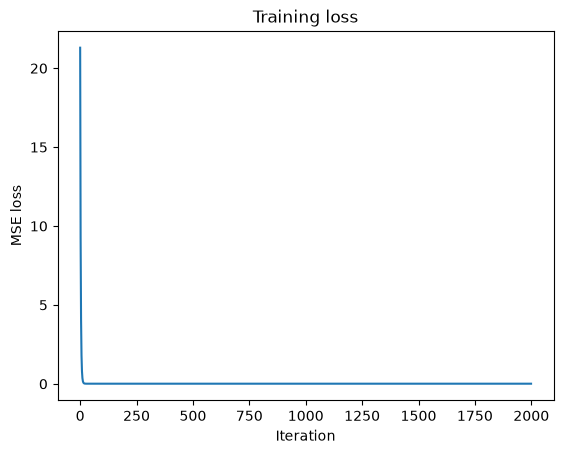

In [14]:
import matplotlib.pyplot as plt

plt.plot(model.history)
plt.xlabel("Iteration")
plt.ylabel("MSE loss")
plt.title("Training loss")
plt.show()